In [10]:
import matplotlib.pyplot as plt
import numpy as np
from superfv.tools.stability_analysis.rk import compute_rk_amplification

In [11]:
def plot_amplification_values(ax, p, k_values, cfl_values, scheme, rk, operator, **kwargs):
    data = []
    for cfl_val in cfl_values:
        max_amplification = compute_rk_amplification(p, k_values, cfl_value=cfl_val, scheme=scheme, rk=rk, operator=operator)
        data.append(max_amplification)
    y = np.array(data)

    ax.plot(cfl_values, y, **kwargs)

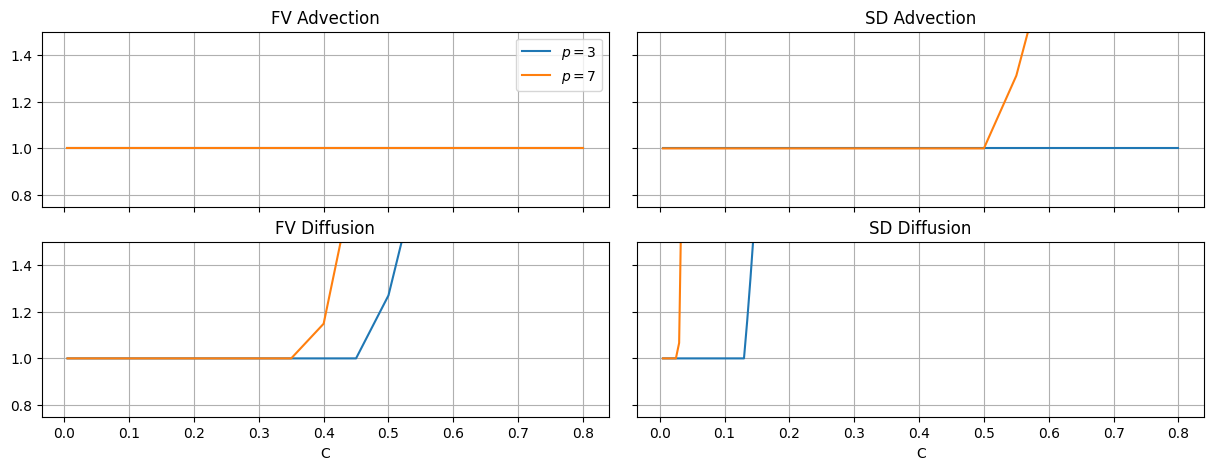

In [ ]:
cfl_values = np.concatenate([np.arange(0.005, 0.205, 0.005), np.arange(0.25, 0.85, 0.05)])
k_values = np.linspace(0, 2 * np.pi, 100)

fig, axs = plt.subplots(2, 2, sharex='col', sharey=True, figsize=(15, 5))
axs[0, 0].set_ylim(0.75, 1.5)
axs[1, 0].set_xlabel("C")
axs[1, 1].set_xlabel("C")

axs[0, 0].set_title("FV Advection")
plot_amplification_values(axs[0, 0], 3, k_values, cfl_values, "fv", "ssprk3", "advection", label=r"$p=3$")
plot_amplification_values(axs[0, 0], 7, k_values, cfl_values, "fv", "ssprk3", "advection", label=r"$p=7$")

axs[1, 0].set_title("FV Diffusion")
plot_amplification_values(axs[1, 0], 3, k_values, cfl_values, "fv", "ssprk3", "diffusion", label=r"$p=3$")
plot_amplification_values(axs[1, 0], 7, k_values, cfl_values, "fv", "ssprk3", "diffusion", label=r"$p=7$")

axs[0, 1].set_title("SD Advection")
plot_amplification_values(axs[0, 1], 3, k_values, cfl_values, "sd", "ssprk3", "advection", label=r"$p=3$")
plot_amplification_values(axs[0, 1], 7, k_values, cfl_values, "sd", "ssprk3", "advection", label=r"$p=7$")

axs[1, 1].set_title("SD Diffusion")
plot_amplification_values(axs[1, 1], 3, k_values, cfl_values, "sd", "ssprk3", "diffusion", label=r"$p=3$")
plot_amplification_values(axs[1, 1], 7, k_values, cfl_values, "sd", "ssprk3", "diffusion", label=r"$p=7$")

axs[0, 0].legend()
for ax in axs.flat:
    ax.grid()

plt.subplots_adjust(hspace=0.2, wspace=0.05)